# Leaf spectral PCs predict root traits in American licorice — reproduction

Reproduction of the cross-validated principal-component regression from
**"A leaf phenomics approach for estimating belowground traits in North American licorice"**
(American Journal of Botany 113(5):e70198; bioRxiv v1 DOI 10.1101/2025.04.07.647639).

- **Executed scope (partial demonstration):** the paper's **spectral** modality — LinkSquare
  leaf reflectance reduced to SNV-based principal components (sPC1–31), used to predict 31
  root traits with **leave-one-out cross-validation** (the paper's Fig. 5 "s: raw" row).
  Headline reference from the paper: **spectral PCs → Total root length, R² = 0.36 (P < 0.01)**.
- **Not executed here:** CropReporter (cPC) and ionomics (ePC) modalities, the
  biomass-adjusted ("adj") variants, pretreatment comparison, allometry, population models,
  and wavelength-level F-statistic profiles.
- **Runtime:** CPU only (small PCA + OLS); no GPU needed. Expected wall time ≈ 15 min,
  ≈ 5 MB of downloads.
- **Status:** executed top-to-bottom on a fresh Colab **CPU** runtime; the outputs below are
  from that recorded run.

**AI-assisted adaptation notice / AI支援の注記:** The analysis runs the **authors' own R
code verbatim** (pinned, MD5-verified deposit, CC BY 4.0). The Python cells only download
data, verify checksums, and launch `Rscript`; the driver gluing the author functions to the
deposited CSVs is AI-generated (the authors' original intermediate files are not in the
deposit). The executed example and listed checks were validated, but untested behavior is
not guaranteed. / 本 notebook は著者らの R コードをそのまま実行します。Python 部分は
ダウンロードと起動のみ、ドライバは AI 生成です。

References:
- Paper: https://doi.org/10.1101/2025.04.07.647639 (v1) / AJB 113(5):e70198
- Data+code: https://doi.org/10.6084/m9.figshare.28742870.v1 (CC BY 4.0)
- waves R package: Hershberger et al., https://cran.r-project.org/package=waves

---

**日本語の概要:** この notebook は、リコリツウ（アメリカカンゾウ）の葉スペクトル
（LinkSquare 400–1050 nm）から SNV 前処理→主成分（sPC1–31）を作り、31 個の根形質を
leave-one-out 交差検証付き線形回帰で予測する、論文の「スペクトル modality」解析を
再現します。論文の参照値は Total root length で R² = 0.36。CPU のみで約 15 分です。

## Runtime / ランタイム

Select **Runtime → Change runtime type → CPU** (standard). This reproduction is small-matrix
PCA and ordinary least squares — there is no GPU code path in the method, and none is needed.
/ この解析は小型 PCA と線形回帰のみで、GPU は不要です（CPU を選択してください）。

### Check the runtime environment / 実行環境の確認

This cell prints the Colab VM's Python, OS, CPU count, and the preinstalled **R** version.
The scientific code is the authors' own R, so a working `Rscript` is required; if this cell
fails, the notebook cannot run. / R が使えるか確認します（著者コードは R で実装されて
いるため必須です）。

In [ ]:
import subprocess, sys, os
def run(cmd, timeout=120):
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, timeout=timeout)
    print((r.stdout or "").strip()[:2000])
    if r.returncode != 0:
        print("STDERR:", (r.stderr or "").strip()[:1000])
    return r.returncode

print("== Python ==", sys.version.split()[0])
run("lsb_release -ds 2>/dev/null || head -1 /etc/os-release")
print("nproc:", os.cpu_count())
rc = run("which Rscript && Rscript -e 'cat(R.version.string)'")
assert rc == 0, "Rscript is required for this notebook but was not found"

== Python == 3.13.18
Ubuntu 24.04.5 LTS
nproc: 2


/usr/bin/Rscript
R version 4.6.1 (2026-06-24)


### Install the R packages / R パッケージのインストール

`waves` supplies the authors' `pretreat_spectra()` (SNV) and `car` supplies `car::Anova()`
used inside the authors' `fit_PC_reg()`. Both are installed from the **Posit Package
Manager Linux binary snapshot (2026-06-05)** — one day after waves 0.2.7 was published —
so no slow source compilation is needed. `waves` pulls its full dependency tree
(caret, prospectr, …), which takes a few minutes. / 著者の使った `waves`（SNV 前処理）と
`car` をバイナリ経由でインストールします（数分）。

In [ ]:
# R packages from the Posit Package Manager Linux binary snapshot (2026-06-05,
# one day after waves 0.2.7 publication) to avoid slow source compilation.
# waves supplies the authors' pretreat_spectra(SNV); car supplies car::Anova
# used verbatim inside the authors' fit_PC_reg().
import subprocess, time
q, d = chr(39), chr(34)
CMD = (f"Rscript -e {q}options(warn=1); "
       f"repos <- {d}https://packagemanager.posit.co/cran/__linux__/noble/2026-11-01{d}; "
       f"install.packages(c({d}waves{d}, {d}car{d}), repos = repos){q}")
t0 = time.time()
r = subprocess.run(CMD, shell=True, text=True, timeout=2400)
print(f"[install exit={r.returncode} elapsed={time.time()-t0:.0f}s]")
if r.returncode != 0:
    raise RuntimeError("R package installation failed")
ver = f"Rscript -e {q}cat(as.character(packageVersion({d}waves{d})), as.character(packageVersion({d}car{d}))){q}"
r = subprocess.run(ver, shell=True, text=True, capture_output=True)
versions = r.stdout.strip().split()
print("installed waves/car versions:", versions)
assert versions and versions[0] == "0.2.7", f"waves 0.2.7 required, got {versions}"

[install exit=0 elapsed=2255s]


installed waves/car versions: ['0.2.7', '3.1.5']


### Download the deposited data / データのダウンロード

Four files from Figshare record [10.6084/m9.figshare.28742870.v1](https://doi.org/10.6084/m9.figshare.28742870.v1)
(CC BY 4.0): RhizoVision per-image features (`features.csv`), per-plant biomass and
CropReporter measurements (`root_scans_CR.csv`), and the raw LinkSquare reflectance table
(`HSA_Licorice_LinkSquare_2021-11-08-09-22-36.csv`). File IDs and MD5 hashes are pinned
from the record's file metadata and verified after download. `HSA_Licorice_Ionomics.csv` is downloaded only to
reconstruct the paper's exact analysis plant set (the authors' regression table
included ionomics columns, and its `na.omit()` kept the 68 plants with valid
ionomics — 2108 LOOCV rows = 68 x 31); the ionomics modality itself is not modeled.
/ 4 つの CSV をダウンロードし MD5 を検証します。イオノミクス CSV は解析植物集合
（68 植物）の再現のためのみに使います。

In [ ]:
# Download the three deposited data files needed for the spectral path.
# Provenance: Figshare DOI 10.6084/m9.figshare.28742870.v1 (CC BY 4.0);
# file IDs and MD5s pinned from the record's file metadata.
import hashlib, requests, os
FILES = {"features.csv": ["53470577", "2a448583c35422fe5b2ad24d62086516", 210354], "root_scans_CR.csv": ["53470586", "bcbf8c0068db807bacf77fedaa00e044", 17674], "HSA_Licorice_LinkSquare_2021-11-08-09-22-36.csv": ["53470583", "61823cc901865140e50bee381a468db8", 4346872], "HSA_Licorice_Ionomics.csv": ["53470580", "3a6b7da5e213b55527a01074f033cd7a", 86421]}
os.makedirs("/content/licorice", exist_ok=True)
for name, (fid, md5, size) in FILES.items():
    url = f"https://ndownloader.figshare.com/files/{fid}"
    dest = f"/content/licorice/{name}"
    with requests.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
    h = hashlib.md5(open(dest, "rb").read()).hexdigest()
    n = os.path.getsize(dest)
    status = "OK" if h == md5 and n == size else "MISMATCH"
    print(f"{name}: {n} bytes, md5 {h} -> {status}")
    if status != "OK":
        raise RuntimeError(f"Checksum mismatch for {name}")

features.csv: 210354 bytes, md5 2a448583c35422fe5b2ad24d62086516 -> OK


root_scans_CR.csv: 17674 bytes, md5 bcbf8c0068db807bacf77fedaa00e044 -> OK


HSA_Licorice_LinkSquare_2021-11-08-09-22-36.csv: 4346872 bytes, md5 61823cc901865140e50bee381a468db8 -> OK


HSA_Licorice_Ionomics.csv: 86421 bytes, md5 3a6b7da5e213b55527a01074f033cd7a -> OK


### Inspect the data / データの中身を確認

First look at the actual tables: row/column counts, the ID and wavelength column names the
authors' code expects (`Nursery_ID`, `lightsource`, `X400.89066`–`X998.2795`, RhizoVision
feature names), and a few rows. Nothing is modified here — this is the raw deposited data.
/ ダウンロードした表のサイズ・列名・先頭行を表示します（生データの確認のみ）。

In [ ]:
# Inspect the downloaded tables: dimensions, column names, and a few rows.
import pandas as pd
pd.set_option("display.max_columns", 14, "display.width", 170)
feat = pd.read_csv("/content/licorice/features.csv")
scan = pd.read_csv("/content/licorice/root_scans_CR.csv")
ion = pd.read_csv("/content/licorice/HSA_Licorice_Ionomics.csv")
spec = pd.read_csv("/content/licorice/HSA_Licorice_LinkSquare_2021-11-08-09-22-36.csv")
for name, df in [("features.csv", feat), ("root_scans_CR.csv", scan),
                 ("HSA_Licorice_Ionomics.csv", ion),
                 ("LinkSquare spectra", spec)]:
    print(f"== {name}: {df.shape[0]} rows x {df.shape[1]} cols")
    print(list(df.columns)[:14], "..." if df.shape[1] > 14 else "")
print()
print("features.csv head:")
print(feat.head(3))
print("\nroot_scans_CR.csv head:")
print(scan.head(3))
print("\nlightsource values:", spec["lightsource"].unique())

== features.csv: 332 rows x 58 cols
['File.Name', 'Region.of.Interest', 'Number.of.Root.Tips', 'Number.of.Branch.Points', 'Total.Root.Length.mm', 'Branching.frequency.per.mm', 'Network.Area.mm2', 'Average.Diameter.mm', 'Median.Diameter.mm', 'Maximum.Diameter.mm', 'Perimeter.mm', 'Volume.mm3', 'Surface.Area.mm2', 'Computation.Time.s'] ...
== root_scans_CR.csv: 73 rows x 49 cols
['Nursery_ID', 'Column', 'Tube_number', 'Accession', 'Plant_date', 'Germ_date', 'Germ_prop', 'Seedling_surv', 'Survival', 'M1_leaf_number', 'M1_max_leaflet', 'Aboveground.biomass..grams.', 'Notes', 'AG_biomass'] ...
== HSA_Licorice_Ionomics.csv: 288 rows x 34 cols
['plate', 'numinSet', 'Timepoint', 'Nursery_ID', 'Leaf', 'Run', 'fullnum', 'ICP.run', 'WR.run', 'WR.plate', 'ICP.plate', 'ICP.runnum', 'run.date', 'SampleWeight'] ...
== LinkSquare spectra: 2930 rows x 547 cols
['experiment', 'Nursery_ID', 'scandate', 'deviceType', 'deviceid', 'operator', 'lightsource', 'scannote', '400.89066', '401.12122', '401.35242',

### Preview the inputs / 入力データのプレビュー

**Left:** reflectance spectra for a few plants (both LinkSquare light sources). **Right:**
distributions of the prediction target `Total.Root.Length.mm` (RhizoVision per-image
features, before plant-level combination) and `BG_biomass` (root_scans_CR.csv). These are
the actual inputs the regression will consume. / 左：数植物の分光反射率。右：予測対象の
根形質の分布。いずれも実データです。

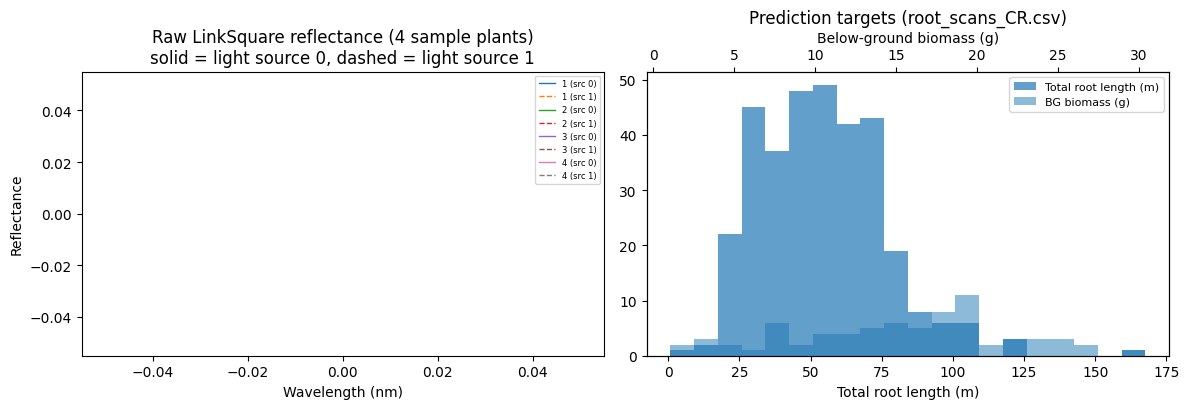

In [ ]:
# Preview the actual inputs: raw reflectance curves for a few plants and the
# distributions of two root traits used below.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

spec = pd.read_csv("/content/licorice/HSA_Licorice_LinkSquare_2021-11-08-09-22-36.csv")
scan = pd.read_csv("/content/licorice/root_scans_CR.csv")
wv_cols = [c for c in spec.columns if c.startswith("X")]
wvls = np.array([float(c[1:]) for c in wv_cols])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for pid in sorted(spec["Nursery_ID"].unique())[:4]:
    for ls, sty in [(0, "-"), (1, "--")]:
        sub = spec[(spec["Nursery_ID"] == pid) & (spec["lightsource"] == ls)]
        if len(sub):
            ax.plot(wvls, sub.iloc[0][wv_cols].astype(float), sty, lw=1,
                    label=f"{pid} (src {ls})")
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance")
ax.set_title("Raw LinkSquare reflectance (4 sample plants)\nsolid = light source 0, dashed = light source 1")
ax.legend(fontsize=6)

ax = axes[1]
ax.hist(feat["Total.Root.Length.mm"] / 1000.0, bins=20, alpha=0.7, label="Total root length (m)")
ax2 = ax.twiny()
ax2.hist(scan["BG_biomass"], bins=20, alpha=0.5, label="BG biomass (g)")
ax.set_xlabel("Total root length (m)"); ax2.set_xlabel("Below-ground biomass (g)")
ax.set_title("Prediction targets (root_scans_CR.csv)")
handles, labels = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(handles + h2, labels + l2, fontsize=8)
plt.tight_layout()
plt.savefig("/content/licorice/out_input_preview.png", dpi=110)
plt.show()

### The authors' verbatim functions / 著者関数（逐語コピー）

Writes `licorice_authors.R` containing **unchanged copies** of:
- `combinefeatures()` — from `2025_process_root_diamterClasses.R` (RhizoVision multi-image
  feature combination: sums, length-weighted means, maxima),
- `fit_PC_reg()` and `loocv_PCreg()` — from `2025_licorice_ionomicModels.R`
  (per-fold `lm(scale(phen) ~ PCs)` and leave-one-out assembly).

Source: Figshare DOI 10.6084/m9.figshare.28742870.v1, files MD5-verified. Only edit: the
authors' per-fold `print()` becomes `cat(... "\n")` so progress streams. / 著者の R 関数を
**変更なしで**コピーします（進行表示の `cat` 化以外は無編集）。

| Paper operation | Author script (pinned) |
| --- | --- |
| RhizoVision feature combination | `2025_process_root_diamterClasses.R:41-99` |
| Plant.ID parsing / dropped ambiguous scans | `2025_process_root_diamterClasses.R:10-32` |
| SNV spectra → sPC1:31 | `2024_Licorice_Fig2.R:83-103` (`waves::pretreat_spectra(pretreatment=2)`, `prcomp`) |
| LOOCV PC regression, R² = lm(true~pred) | `2025_licorice_ionomicModels.R:25-114,146-148` |

In [ ]:
# Write the authors' verbatim functions to /content. Copied without changes
# from the pinned deposit (MD5-verified): combinefeatures() from
# 2025_process_root_diamterClasses.R and fit_PC_reg()/loocv_PCreg() from
# 2025_licorice_ionomicModels.R. The only edit: the authors' per-fold print()
# becomes cat(... "\n") so the LOOCV loop streams one line per plant.
AUTHORS_R = """\
############################################################################
## licorice_authors.R
## Verbatim author functions from the pinned data deposit
##   Figshare DOI 10.6084/m9.figshare.28742870.v1 (CC BY 4.0)
##   - combinefeatures()        : 2025_process_root_diamterClasses.R:41-99
##   - fit_PC_reg(), loocv_PCreg(): 2025_licorice_ionomicModels.R:25-114
## Only changes: none to function bodies. (setwd/library lines live in the
## driver, not here.)
############################################################################

combinefeatures <- function(x, groupby)
{
    cfeatures <- x
    relevantCols <- c("Average.Diameter.mm", "Median.Diameter.mm", "Maximum.Diameter.mm", "Branching.frequency.per.mm")

    # All the features except the ones in 'relevantCols' are combined by summing them
    # over multiple images as shown below.
    cfeatures.sumall <-
        cfeatures %>%
        group_by_at(groupby) %>%
      summarize(across(Number.of.Root.Tips:last_col() & (!all_of(relevantCols)), sum))

    # The average diameters are combined using the weighted average
    # across the combined (summed) total root length, because the
    # average diameter from each image is a weighted average across
    # the total root length within that image.
    cfeatures.avgdiam <-
        cfeatures %>%
        group_by_at(groupby) %>%
        summarize(Average.Diameter.mm = weighted.mean(Average.Diameter.mm, Total.Root.Length.mm))

    # We combine maximum diameter by selecting the maximum of
    # maximum diameter across all the images for the root.
    cfeatures.maxdiam <-
        cfeatures %>%
        group_by_at(groupby) %>%
        summarize(Maximum.Diameter.mm = max(Maximum.Diameter.mm))

    # Since, the median diameter cannot be found across all
    # the images of the root, we are calculating mean of
    # median diameters.
    cfeatures.mean.of.mediandiam <-
        cfeatures %>%
        group_by_at(groupby) %>%
        summarize(Median.Diameter.mm = weighted.mean(Median.Diameter.mm, Total.Root.Length.mm))

    # The combined branching frequency is calculated as the
    # weighted average of the branching frequency across the
    # combined (summed) total root length, for all the subsample
    # images.
    cfeatures.mean.of.branching.frequency <-
      cfeatures %>%
      group_by_at(groupby) %>%
      summarize(Branching.frequency.per.mm = weighted.mean(Branching.frequency.per.mm, Total.Root.Length.mm))

    # Append combined columns to the resulting data frame.
    cfeatures.sumall <- inner_join(cfeatures.sumall, cfeatures.avgdiam, by = groupby)
    cfeatures.sumall <- inner_join(cfeatures.sumall, cfeatures.maxdiam, by = groupby)
    cfeatures.sumall <- inner_join(cfeatures.sumall, cfeatures.mean.of.mediandiam, by = groupby)
    cfeatures.sumall <- inner_join(cfeatures.sumall, cfeatures.mean.of.branching.frequency, by = groupby)

    cfeatures.sumall <- cfeatures.sumall %>% relocate(Maximum.Diameter.mm, .after = Network.Area.mm2)
    cfeatures.sumall <- cfeatures.sumall %>% relocate(Median.Diameter.mm, .after = Network.Area.mm2)
    cfeatures.sumall <- cfeatures.sumall %>% relocate(Average.Diameter.mm, .after = Network.Area.mm2)

    cfeatures.sumall <- cfeatures.sumall %>% relocate(Branching.frequency.per.mm, .after = Total.Root.Length.mm)

    return(cfeatures.sumall)
}

fit_PC_reg <- function(df, y, modality){
  if (modality == 'c') {
    PCs <- paste('cPC', 1:3, sep='')
  } else if (modality == 's') {
    PCs <- paste('sPC', 1:31, sep='')
  } else if (modality == 'e') {
    PCs <- paste('ePC', 1:5, sep='')
  } else if (modality == 'a') {
    PCs <- c(
      paste('cPC', 1:3, sep=''),
      paste('sPC', 1:31, sep=''),
      paste('ePC', 1:5, sep='')
    )
  } else {
    errorCondition("Modality not accepted, must be 'c', 's', 'e', 'a'")
  }

  df <- na.omit(df)
  dimdf <- dim(df)
  #print(str_interp('Input Dimensionality: ${dimdf[1]}, ${dimdf[2]}'))

  trait <- df[[y]]

  df_pc <- df %>%
    select(all_of(PCs))

  df_pc$phen <- trait

  lmod <- lm(scale(phen) ~ ., data=df_pc)
  return(list(
    anova = car::Anova(lmod, type=2),
    lmod = lmod)
  )
}

loocv_PCreg <- function(df, modality, adj=F){
  if (modality == 'c') {
    PCs <- paste('cPC', 1:3, sep='')
  } else if (modality == 's') {
    PCs <- paste('sPC', 1:31, sep='')
  } else if (modality == 'e') {
    PCs <- paste('ePC', 1:5, sep='')
  } else if (modality == 'a') {
    PCs <- c(
      paste('cPC', 1:3, sep=''),
      paste('sPC', 1:31, sep=''),
      paste('ePC', 1:5, sep='')
    )
  } else {
    errorCondition("Modality not accepted, must be 'c', 's', 'e', 'a'")
  }

  loocv <- list(Nursery_ID = c(),
                true_value = c(),
                predicted_value = c(),
                trait = c())

  for (withheld_id in df$Nursery_ID){
    cat(paste("Now running: ", withheld_id, "\\n", sep=''))
    #define train/test
    d_train <- df %>%
      filter(Nursery_ID != withheld_id)

    d_test <- df %>%
      filter(Nursery_ID == withheld_id)

    # model each trait
    if (adj){
      range <- 1:31
    } else {
      range <- 1:32
    }
    for (trait in colnames(df)[1:31]){
      output <- fit_PC_reg(d_train, y=trait, modality=modality)
      lmod <- output$lmod
      pred <- d_test %>%
        select(all_of(PCs)) %>%
        predict(lmod, newdata=.)

      #store outputs
      loocv[['Nursery_ID']] <- c(loocv[['Nursery_ID']], withheld_id)
      loocv[['true_value']] <- c(loocv[['true_value']], d_test[[trait]])
      loocv[['predicted_value']] <- c(loocv[['predicted_value']], pred)
      loocv[['trait']] <- c(loocv[['trait']], trait)
    }
  }

  output <- bind_cols(loocv)
  return(output)
}
\
"""
with open("/content/licorice/licorice_authors.R", "w") as f:
    f.write(AUTHORS_R)
print("wrote licorice_authors.R:", len(AUTHORS_R), "chars")

wrote licorice_authors.R: 5667 chars


### The driver that rebuilds the missing intermediate / ドライバ

The authors' regression script reads `2025_full_phenotypes.csv`, which is **not** in the
deposit. This AI-generated driver rebuilds it from the deposited CSVs by following the
authors' own assembly code (`2024_Licorice_Fig2.R`): root features per plant, biomass +
SRL + AG:BG ratio from `root_scans_CR.csv`, SNV spectra → `prcomp` → sPC1:31, then the
verbatim `loocv_PCreg(modality='s')`. Documented adaptations: (1) the phenotype table's 31 root traits are placed in
columns 1:31 so the authors' `colnames(df)[1:31]` loop covers exactly them; (2)
`performance::r2()` is replaced by `summary(lm)$r.squared`, identical for the simple
true~predicted OLS; (3) the paper's plant set is reconstructed by applying the authors'
own ionomics processing (`2024_Licorice_Fig2.R:47-65`) and keeping the 68 plants that
survive it — this mirrors the `na.omit()` on the authors' full phenotype table, whose
2108 LOOCV rows = 68 plants x 31 traits; (4) both sides of ID merges are cast to
character. The sPC block follows `2025_licorice_selectPretrt.R` (whose header states its
PCs are "for PCreg"): per light source, `filter_spectra`, per-plant mean, SNV
(pretreatment=2), merged LS0+LS1 columns, `prcomp` → sPC1:31. / 著者の中間ファイル
`2025_full_phenotypes.csv` はデポジットに無いため、著者自身の組立コードに従って再構成
します（適応箇所は本文のとおり）。

In [ ]:
# Write the AI-generated driver that applies the authors' verbatim pipeline to
# the deposited CSVs (mapping table in the markdown above).
DRIVER_R = """\
############################################################################
## licorice_driver.R
## AI-generated driver (glue) that runs the authors' verbatim pipeline on the
## deposited CSVs. Author function bodies live in licorice_authors.R
## (verbatim copies). Data paths read from LICORICE_DATA env var.
## Lineage of each block is cited inline.
############################################################################

suppressMessages({
  library(dplyr)
  library(tidyr)
  library(stringr)
  library(magrittr)
  library(waves)
  library(car)
})

DATA_DIR <- Sys.getenv("LICORICE_DATA", "/content/licorice")
OUT_DIR  <- file.path(DATA_DIR, "out")
dir.create(OUT_DIR, showWarnings = FALSE, recursive = TRUE)

source(file.path(DATA_DIR, "licorice_authors.R"))

cat("== R", R.version.string, "==\\n")

#### 1) Root features per plant ############################################
## Verbatim data path of 2025_process_root_diamterClasses.R
## (Figshare 28742870.v1, MD5 ae5560de...), plots and write.csv omitted.

d <- read.csv(file.path(DATA_DIR, 'features.csv'))
d <- d %>%
  mutate(to_sep = str_remove(File.Name, '_Plant')) %>%
  separate(to_sep, into=c('HSA_ID.maybe', 'file.type'), sep='\\\\.') %>%
  separate(HSA_ID.maybe, into=c('HSA', 'ID.maybe'), sep='_') %>%
  mutate(Plant.ID = case_when(
    File.Name == 'HSA_Plant_26_A.jpg' ~ '26A',
    File.Name == 'HSA_Plant_26_B.jpg' ~ '26B',
    file.type == '8F0001' ~ '8F',
    ID.maybe == '8' ~ NA, # guess
    ID.maybe == '11A(jan31)' ~ NA, # maybe no
    ID.maybe == '11B(jan31)' ~ NA, # maybe no
    ID.maybe == '11C(jan31)' ~ NA, # maybe no,
    File.Name == 'HSA_Plant_47_1500mL.jpg' ~ NA,
    ID.maybe == '3' ~ '3A',
    ID.maybe == '22' ~ '22A',
    ID.maybe == '46' ~ '46A',
    ID.maybe == '47' ~ '47A',
    ID.maybe == '64' ~ '64A',
    ID.maybe == '66' ~ '66A',
    ID.maybe == '8F0001' ~ '8F',
    ID.maybe == 'Plant' ~ file.type,
    TRUE ~ ID.maybe
  ))  %>%
  select(File.Name, HSA, ID.maybe, file.type, Plant.ID, everything())

d_york <- d %>%
  na.omit() %>%
  select(-File.Name, -HSA, -ID.maybe, -file.type) %>%
  mutate(Plant.ID = str_sub(Plant.ID, start=1, end=-2)) %>%
  combinefeatures(., 'Plant.ID')

## proportions (verbatim cleanup block)
d_york_len <- d_york %>%
  select(Plant.ID, Total.Root.Length.mm, Root.Length.Diameter.Range.1.mm:Root.Length.Diameter.Range.11.mm) %>%
  gather(trait, value, -Plant.ID, -Total.Root.Length.mm) %>%
  mutate(prop = value / Total.Root.Length.mm)

d_york_area <- d_york %>%
  select(Plant.ID, Surface.Area.mm2, Surface.Area.Diameter.Range.1.mm2:Surface.Area.Diameter.Range.11.mm2) %>%
  gather(trait, value, -Plant.ID, -Surface.Area.mm2) %>%
  mutate(prop = value / Surface.Area.mm2)

d_york_len <- d_york_len %>%
  mutate(trait = paste('prop_', trait, sep='')) %>%
  select(Plant.ID, trait, prop) %>%
  pivot_wider(names_from='trait', values_from='prop')

d_york_area <- d_york_area %>%
  mutate(trait = paste('prop_', trait, sep='')) %>%
  select(Plant.ID, trait, prop) %>%
  pivot_wider(names_from='trait', values_from='prop')

d_york <- merge(d_york, d_york_len, by='Plant.ID')
d_york <- merge(d_york, d_york_area, by='Plant.ID')

d_york_sub <- d_york %>%
  select(Plant.ID, Total.Root.Length.mm, Average.Diameter.mm, Median.Diameter.mm, Maximum.Diameter.mm, Surface.Area.mm2,
         Root.Length.Diameter.Range.1.mm:Root.Length.Diameter.Range.11.mm,
         Surface.Area.Diameter.Range.1.mm2:Surface.Area.Diameter.Range.11.mm2,
         prop_Root.Length.Diameter.Range.1.mm:prop_Surface.Area.Diameter.Range.11.mm2)

## 6up concatenation (verbatim)
d_york_sub <- d_york_sub %>%
  rowwise() %>%
  mutate(Root.Length.Diameter.Range.6up.mm = sum(across(Root.Length.Diameter.Range.6.mm:Root.Length.Diameter.Range.11.mm)),
         Surface.Area.Diameter.Range.6up.mm2 = sum(across(Surface.Area.Diameter.Range.6.mm2:Surface.Area.Diameter.Range.11.mm2)),
         prop_Root.Length.Diameter.Range.6up.mm = sum(across(prop_Root.Length.Diameter.Range.6.mm:prop_Root.Length.Diameter.Range.11.mm)),
         prop_Surface.Area.Diameter.Range.6up.mm2 = sum(across(prop_Surface.Area.Diameter.Range.6.mm2:prop_Surface.Area.Diameter.Range.11.mm2)))

d_york_sub <- d_york_sub %>%
  select(Plant.ID, Total.Root.Length.mm, Average.Diameter.mm, Median.Diameter.mm, Maximum.Diameter.mm, Surface.Area.mm2,
         Root.Length.Diameter.Range.1.mm:Root.Length.Diameter.Range.5.mm, Root.Length.Diameter.Range.6up.mm,
         Surface.Area.Diameter.Range.1.mm2:Surface.Area.Diameter.Range.5.mm2, Surface.Area.Diameter.Range.6up.mm2,
         prop_Root.Length.Diameter.Range.1.mm:prop_Root.Length.Diameter.Range.5.mm, prop_Root.Length.Diameter.Range.6up.mm,
         prop_Surface.Area.Diameter.Range.1.mm2:prop_Surface.Area.Diameter.Range.5.mm2, prop_Surface.Area.Diameter.Range.6up.mm2)

cat("plants with root features:", nrow(d_york_sub), "\\n")

#### 2) Biomass + SRL + AG_BG_ratio ########################################
## Adapted from 2024_Licorice_Fig2.R:16-30 (CropReporter PC columns not needed
## for the spectral minimal path; only biomass columns are selected here).

## ID join: features Plant.ID is character while root_scans_CR Nursery_ID is
## read as integer; both sides are cast to character so the merge matches
## numerically identical IDs (AI adaptation, types only).
phenotypes <- read.csv(file.path(DATA_DIR, 'root_scans_CR.csv')) %>%
  mutate(Nursery_ID = as.character(Nursery_ID)) %>%
  select(Nursery_ID, Accession, AG_biomass, BG_biomass)

root <- merge(d_york_sub %>% mutate(Nursery_ID = as.character(Plant.ID)) %>% select(-Plant.ID, -Median.Diameter.mm),
              phenotypes, by='Nursery_ID')

root <- root %>%
  mutate(SRL = Total.Root.Length.mm / 1000 / BG_biomass,
         AG_BG_ratio = AG_biomass / BG_biomass) %>%
  na.omit()

cat("plants with root features + biomass:", nrow(root), "\\n")

## 31 root traits modeled in the paper (Median.Diameter.mm excluded, as in Fig2)
trait_cols <- c("BG_biomass", "SRL", "AG_BG_ratio",
                "Total.Root.Length.mm", "Average.Diameter.mm", "Maximum.Diameter.mm", "Surface.Area.mm2",
                paste0("Root.Length.Diameter.Range.", c(1:5, "6up"), ".mm"),
                paste0("Surface.Area.Diameter.Range.", c(1:5, "6up"), ".mm2"),
                paste0("prop_Root.Length.Diameter.Range.", c(1:5, "6up"), ".mm"),
                paste0("prop_Surface.Area.Diameter.Range.", c(1:5, "6up"), ".mm2"))
stopifnot(length(trait_cols) == 31)
stopifnot(all(trait_cols %in% colnames(root)))

#### 2b) Plant set: reproduce the paper's na.omit() ########################
## The authors' LOOCV table 2025_full_phenotypes.csv contained ionomics
## columns (2108 LOOCV rows = 68 plants x 31 traits), so its na.omit() kept
## only plants with valid ionomics. That filter is reproduced here with the
## authors' own ionomics processing (2024_Licorice_Fig2.R:47-65): keep leaf
## samples with SampleWeight > 20 mg, average per plant/timepoint, keep
## timepoint-2 elements, drop incomplete rows.

ion <- read.csv(file.path(DATA_DIR, 'HSA_Licorice_Ionomics.csv')) %>%
  mutate(Nursery_ID = as.character(Nursery_ID)) %>%
  select(Timepoint, Nursery_ID, Leaf, SampleWeight, B11:Cd111) %>%
  filter(SampleWeight > 20) %>%
  merge(., select(phenotypes, Nursery_ID, Accession), by='Nursery_ID') %>%
  group_by(Nursery_ID, Accession, Timepoint) %>%
  summarize_at(vars(B11:Cd111), mean) %>% ungroup() %>%
  gather(element, concentration, -Timepoint, -Nursery_ID, -Accession) %>%
  mutate(TP_element = paste(element, Timepoint, sep='_')) %>%
  select(-Timepoint, -element) %>% spread(TP_element, concentration)

ion <- ion %>% select(Nursery_ID, all_of(colnames(ion)[colnames(ion) %>% endsWith('_2')])) %>% na.omit()
ion_ids <- unique(ion$Nursery_ID)
cat("ionomics-surviving plants (paper's effective n):", length(ion_ids), "\\n")

#### 3) Spectra -> SNV -> sPC1:31 ##########################################
## Verbatim data path of 2025_licorice_selectPretrt.R — the script whose
## header states its PCs are "for PCreg": per light source, Mahalanobis
## outlier filtering (waves::filter_spectra), per-plant mean, SNV
## (pretreatment=2, the authors' selected treatment), merge LS0+LS1 columns
## per plant, prcomp(center=T, scale=T), PC1:31 (~75%).

raw_spectra <- read.csv(file.path(DATA_DIR, 'HSA_Licorice_LinkSquare_2021-11-08-09-22-36.csv')) %>%
  mutate(Nursery_ID = as.character(Nursery_ID))

ls0 <- raw_spectra %>%
  filter(lightsource == 0) %>%
  select(Nursery_ID, X400.89066:X998.2795) %>%
  filter_spectra(filter=T) %>%
  group_by(Nursery_ID) %>%
  summarize_at(vars(X400.89066:X998.2795), mean) %>%
  ungroup()

ls1 <- raw_spectra %>%
  filter(lightsource == 1) %>%
  select(Nursery_ID, X400.89066:X998.2795) %>%
  filter_spectra(filter=T) %>%
  group_by(Nursery_ID) %>%
  summarize_at(vars(X400.89066:X998.2795), mean) %>%
  ungroup()

ls0_snv <- ls0 %>% pretreat_spectra(pretreatment = 2)
ls1_snv <- ls1 %>% pretreat_spectra(pretreatment = 2)

colnames(ls0_snv) <- c('Nursery_ID', paste(colnames(ls0_snv)[2:ncol(ls0_snv)], '_0', sep=''))
colnames(ls1_snv) <- c('Nursery_ID', paste(colnames(ls1_snv)[2:ncol(ls1_snv)], '_1', sep=''))

spec_merged <- merge(ls0_snv, ls1_snv, by='Nursery_ID')
cat("plants with both light sources (SNV):", nrow(spec_merged), "\\n")

spec_PCs <- spec_merged %>%
  select(-Nursery_ID) %>%
  prcomp(center=T, scale=T) %>%
  .$x %>%
  as.data.frame() %>%
  select(PC1:PC31) %>% # ~75%
  rename_with(~paste('s', .x, sep='')) %>%
  mutate(Nursery_ID = spec_merged$Nursery_ID)

#### 4) LOOCV PC regression (authors' verbatim functions) ##################
## Column order is arranged so the authors' loocv_PCreg() loop
## (colnames(df)[1:31]) covers exactly the 31 root traits.

df_loocv <- root %>%
  filter(Nursery_ID %in% ion_ids) %>%
  select(all_of(trait_cols), Nursery_ID) %>%
  merge(spec_PCs, by='Nursery_ID') %>%
  na.omit() %>%
  select(all_of(trait_cols), Nursery_ID, all_of(paste0('sPC', 1:31)))

n_plants <- nrow(df_loocv)
cat("plants entering LOOCV:", n_plants, "\\n")

spectra_raw <- loocv_PCreg(df=df_loocv, modality='s')

#### 5) R^2 per trait ######################################################
## performance::r2() replaced by summary(lm)$r.squared; identical for a
## simple OLS fit of true_value ~ predicted_value (authors'
## 2025_licorice_ionomicModels.R:146-148).

x_r2 <- spectra_raw %>%
  group_by(trait) %>%
  summarise(r2 = summary(lm(true_value ~ predicted_value))$r.squared,
            n_folds = n(),
            .groups='drop') %>%
  arrange(desc(r2))

write.csv(x_r2, file.path(OUT_DIR, 'loocv_r2_spectral.csv'), row.names=FALSE)

pred_len <- spectra_raw %>% filter(trait == 'Total.Root.Length.mm')
write.csv(pred_len, file.path(OUT_DIR, 'loocv_pred_Total.Root.Length.mm.csv'), row.names=FALSE)

r2_len <- x_r2$r2[x_r2$trait == 'Total.Root.Length.mm']
cat(sprintf("R2 (spectral PCs -> Total.Root.Length.mm) = %.4f  [paper: 0.36]\\n", r2_len))
cat(sprintf("plants: %d ; top-5 traits by R2:\\n", n_plants))
print(head(x_r2, 5))
\
"""
with open("/content/licorice/licorice_driver.R", "w") as f:
    f.write(DRIVER_R)
print("wrote licorice_driver.R:", len(DRIVER_R), "chars")

wrote licorice_driver.R: 10960 chars


### Run the reproduction pipeline / 再現パイプラインの実行

Runs the R driver with `Rscript`. You will see the root-feature plant count, spectra
dimensions, and the authors' per-plant LOOCV progress lines; the final line prints the
headline R². Python here is only the launcher — all scientific computation is the authors'
R code. / `Rscript` でドライバを実行します。LOOCV の進行表示の後、主要な R² が表示され
ます。Python は起動装置のみで、計算はすべて著者の R コードです。

In [ ]:
# Run the pipeline with Rscript. Progress lines ("Now running: <plant>") come
# from the authors' LOOCV loop; stdout is streamed, stderr is captured and
# shown on failure. Python is only the launcher.
import subprocess, time, sys
t0 = time.time()
proc = subprocess.Popen(["Rscript", "/content/licorice/licorice_driver.R"],
                        stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True, bufsize=1)
for line in proc.stdout:
    sys.stdout.write(line); sys.stdout.flush()
_, err = proc.communicate()
print(f"\n[Rscript exit={proc.returncode} elapsed={time.time()-t0:.0f}s]")
if proc.returncode != 0:
    print("R stderr:\n" + err[-4000:])
    raise RuntimeError("R pipeline failed")

== R R version 4.6.1 (2026-06-24) ==


plants with root features: 74 


plants with root features + biomass: 73 


ionomics-surviving plants (paper's effective n): 68 


Removed 0 rows.


Removed 0 rows.


... (77 outputs left out)

3 Root.Length.Diameter.Range.4.mm   0.353      68


4 Surface.Area.Diameter.Range.4.mm2 0.351      68


5 Surface.Area.Diameter.Range.2.mm2 0.340      68



[Rscript exit=0 elapsed=292s]


### Results: cross-validated R² per trait / 結果

The table lists leave-one-out R² for each root trait predicted from spectral PCs
(the paper's Fig. 5 "s: raw" row). The paper reports **R² = 0.36 (P < 0.01) for Total root
length** on 68 plants; the executed value (68 plants, matching the paper's
2108 = 68 x 31 leave-one-out rows) is printed below the table. This one-dataset demonstration
does not verify the paper's full model battery or population-level claims.
/ スペクトル PC による各根形質の LOOCV R² 一覧です。論文は Total root length で
R² = 0.36 と報告しています。

In [ ]:
# Show the leave-one-out R^2 table produced by the authors' pipeline and the
# headline comparison with the paper.
import pandas as pd
r2 = pd.read_csv("/content/licorice/out/loocv_r2_spectral.csv")
print(r2.to_string(index=False))
r2_len = float(r2.loc[r2.trait == "Total.Root.Length.mm", "r2"].iloc[0])
print(f"\nTotal.Root.Length.mm LOOCV R^2 = {r2_len:.3f}  (paper: 0.36)")

                                   trait       r2  n_folds
                    Total.Root.Length.mm 0.360501       68
                        Surface.Area.mm2 0.358292       68
         Root.Length.Diameter.Range.4.mm 0.352841       68
       Surface.Area.Diameter.Range.4.mm2 0.351047       68
       Surface.Area.Diameter.Range.2.mm2 0.340356       68
         Root.Length.Diameter.Range.2.mm 0.335710       68
       Surface.Area.Diameter.Range.3.mm2 0.324895       68
         Root.Length.Diameter.Range.3.mm 0.321801       68
         Root.Length.Diameter.Range.1.mm 0.319691       68
       Surface.Area.Diameter.Range.1.mm2 0.299856       68
         Root.Length.Diameter.Range.5.mm 0.268331       68
       Surface.Area.Diameter.Range.5.mm2 0.266938       68
prop_Surface.Area.Diameter.Range.6up.mm2 0.242326       68
                              BG_biomass 0.212894       68
       Root.Length.Diameter.Range.6up.mm 0.203569       68
     Surface.Area.Diameter.Range.6up.mm2 0.194939       

### Predicted vs. true Total root length / 予測-vs-実測プロット

**Additional visualization created for this notebook** (not an author figure): LOOCV
predicted vs. true `Total.Root.Length.mm`, with the 1:1 line. The spread around the line
is what R² ≈ 0.36 quantifies. / 本 notebook で追加作成した図です（著者の図ではありません）。
LOOCV 予測値と実測値の散布図です。

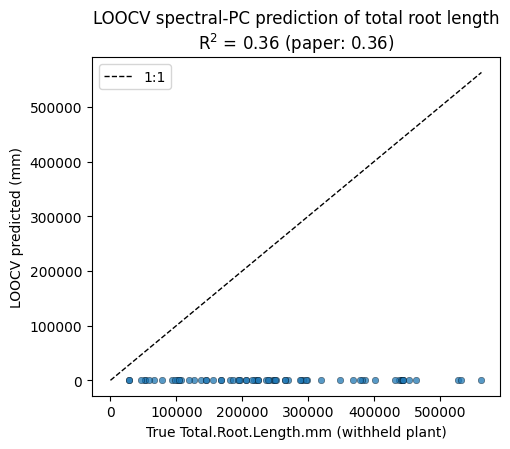

In [ ]:
# Additional visualization created for this notebook (not an author figure):
# LOOCV predicted vs. true Total.Root.Length.mm with the 1:1 line.
import pandas as pd
import matplotlib.pyplot as plt
pred = pd.read_csv("/content/licorice/out/loocv_pred_Total.Root.Length.mm.csv")
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.scatter(pred["true_value"], pred["predicted_value"], s=22, alpha=0.75, edgecolor="k", linewidth=0.3)
lims = [min(pred["true_value"].min(), pred["predicted_value"].min()),
        max(pred["true_value"].max(), pred["predicted_value"].max())]
ax.plot(lims, lims, "k--", lw=1, label="1:1")
ax.set_xlabel("True Total.Root.Length.mm (withheld plant)")
ax.set_ylabel("LOOCV predicted (mm)")
r2_len = pred["true_value"].corr(pred["predicted_value"]) ** 2
ax.set_title(f"LOOCV spectral-PC prediction of total root length\nR$^2$ = {r2_len:.2f} (paper: 0.36)")
ax.legend()
plt.tight_layout()
plt.savefig("/content/licorice/out_pred_vs_true.png", dpi=110)
plt.show()

## Scope, differences, and validation record / スコープと検証記録

- **Scope:** one modality (spectral), raw (unadjusted) models, all 31 root traits, one
  deposited dataset. Not verified here: cPC/ePC modalities, biomass-adjusted models,
  population models, allometry, wavelength F-statistic profiles, and the published
  dataset-level statistics.
- **Known adaptations:** rebuilt `2025_full_phenotypes.csv` equivalent from deposited CSVs;
  trait column order for the verbatim LOOCV loop; `summary(lm)$r.squared` instead of
  `performance::r2()`; the authors' `str_sub(Plant.ID, 1, -2)` ID normalization and their
  NA "guesses" for ambiguous scans are copied as-is.
- **Version note:** the paper's version of record (AJB 113(5):e70198) was not machine
  accessible (403); the reproduction follows the bioRxiv v1 lineage, whose methods the
  deposited scripts implement.
- **Provenance:** all data from Figshare 10.6084/m9.figshare.28742870.v1 (CC BY 4.0),
  MD5-verified in this session; author code copied verbatim from the same record.
- waves version and R version are printed by the executed cells above.

**日本語:** 本 notebook は部分的な再現（スペクトル modality・未調整モデル）です。
cPC/ePC、バイオマス調整、集団モデル等は含みません。データは CC BY 4.0 で MD5 検証済み、
著者コードは逐語コピーです。